### Step 6: Data Cleaning, Transformations & Enhanced EDA in Python 
Objective: Prepare data for analysis and uncover initial trends. 
● Clean the extracted data: 
○ Treat missing values through imputation or removal as justified. 

In [3]:
import pandas as pd

df = pd.read_csv("upi_transaction_history.csv")

df["amount"] = df["amount"].fillna(df["amount"].mean())

df["merchant_id"] = df["merchant_id"].fillna(df["merchant_id"].mode()[0])


df_cleaned = df.dropna()

df_cleaned_specific = df.dropna(subset=["merchant_id"])

valid_merchants = pd.read_csv("merchant_info.csv")["merchant_id"].unique()
df["validation_status"] = df["merchant_id"].apply(
    lambda x: "Needs Review" if pd.isna(x) or x not in valid_merchants else "Valid"
)

df.to_csv("upi_transaction_history_cleaned.csv", index=False)



### Normalize and standardize key numerical fields (e.g., fraud flag, amount). Interpret and document any transformations. 

In [6]:
import pandas as pd
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# Load your dataset (replace with actual file)
df = pd.read_csv("upi_transaction_history.csv")

# --- Normalization (Min-Max scaling to [0,1]) ---
scaler_norm = MinMaxScaler()
df["fraud_flag_normalized"] = scaler_norm.fit_transform(df[["fraud_flag"]])
df["amount_normalized"] = scaler_norm.fit_transform(df[["amount"]])

# --- Standardization (Z-score scaling: mean=0, std=1) ---
scaler_std = StandardScaler()
df["fraud_flag_standardized"] = scaler_std.fit_transform(df[["fraud_flag"]])
df["amount_standardized"] = scaler_std.fit_transform(df[["amount"]])

# Save transformed dataset
df.to_csv("upi_transaction_history_transformed.csv", index=False)
print(df.head())


  transaction_id            upi_id customer_id                   timestamp  \
0    txn10000000    marisa9078@upi  cust101488  2025-06-04 21:36:19.632258   
1    txn10000001  michelle5950@upi  cust107876  2025-05-22 04:26:44.200117   
2    txn10000002   jeffery4732@upi  cust100901  2025-08-02 02:34:14.690327   
3    txn10000003      troy1833@upi  cust105890  2025-01-30 03:53:31.110447   
4    txn10000004     tammy4986@upi  cust106780  2025-07-05 21:36:52.813878   

   amount  transaction_type merchant_id counterparty_upi   status  device_id  \
0    9.88              send         NaN     user6545@upi  success  dev101488   
1   76.25           receive         NaN     user3199@upi  success  dev107876   
2   26.44  merchant_payment   merch1113     user4690@upi  success  dev100901   
3   84.43              send         NaN     user1982@upi  success  dev105890   
4   10.33           receive         NaN     user4914@upi  success  dev106780   

     device_type  channel  fraud_flag  reversal_fl

### Create derived columns (examples only): 
■ Transaction Value per Customer = Total Transaction Amount / 
Number of Transactions
■ Merchant Fraud Ratio = Fraud Transactions / Total Transactions by 
Merchant 
■ Device Fraud Ratio = Fraud Transactions / Total Transactions by 
Device 
■ Transaction Failure Rate = Failed Transactions / Total Transactions 

In [8]:
df["TransactionValuePerCustomer"] = df.groupby("customer_id")["amount"].transform("sum") / \
                                     df.groupby("customer_id")["amount"].transform("count")

df["MerchantFraudRatio"] = df.groupby("merchant_id")["fraud_flag"].transform("sum") / \
                           df.groupby("merchant_id")["fraud_flag"].transform("count")

df["DeviceFraudRatio"] = df.groupby("device_id")["fraud_flag"].transform("sum") / \
                         df.groupby("device_id")["fraud_flag"].transform("count")

df["TransactionFailureRate"] = df.groupby("customer_id")["fraud_flag"].transform("sum") / \
                               df.groupby("customer_id")["fraud_flag"].transform("count")

df.to_csv("upi_transaction_history_with_derived.csv", index=False)
print(df.head())


  transaction_id            upi_id customer_id                   timestamp  \
0    txn10000000    marisa9078@upi  cust101488  2025-06-04 21:36:19.632258   
1    txn10000001  michelle5950@upi  cust107876  2025-05-22 04:26:44.200117   
2    txn10000002   jeffery4732@upi  cust100901  2025-08-02 02:34:14.690327   
3    txn10000003      troy1833@upi  cust105890  2025-01-30 03:53:31.110447   
4    txn10000004     tammy4986@upi  cust106780  2025-07-05 21:36:52.813878   

   amount  transaction_type merchant_id counterparty_upi   status  device_id  \
0    9.88              send         NaN     user6545@upi  success  dev101488   
1   76.25           receive         NaN     user3199@upi  success  dev107876   
2   26.44  merchant_payment   merch1113     user4690@upi  success  dev100901   
3   84.43              send         NaN     user1982@upi  success  dev105890   
4   10.33           receive         NaN     user4914@upi  success  dev106780   

   ... reversal_flag failure_reason  fraud_flag_no

### Perform EDA using pandas, matplotlib, and seaborn: 
○ Visualize trends over time (e.g., daily/monthly transaction/fraud volumes) 
○ Use heatmaps and boxplots to detect regional, merchant, and device-level 
patterns 
○ Summarize metrics using grouped statistics (mean, median, standard 
deviation) 
○ Identify high-activity and high-risk segments

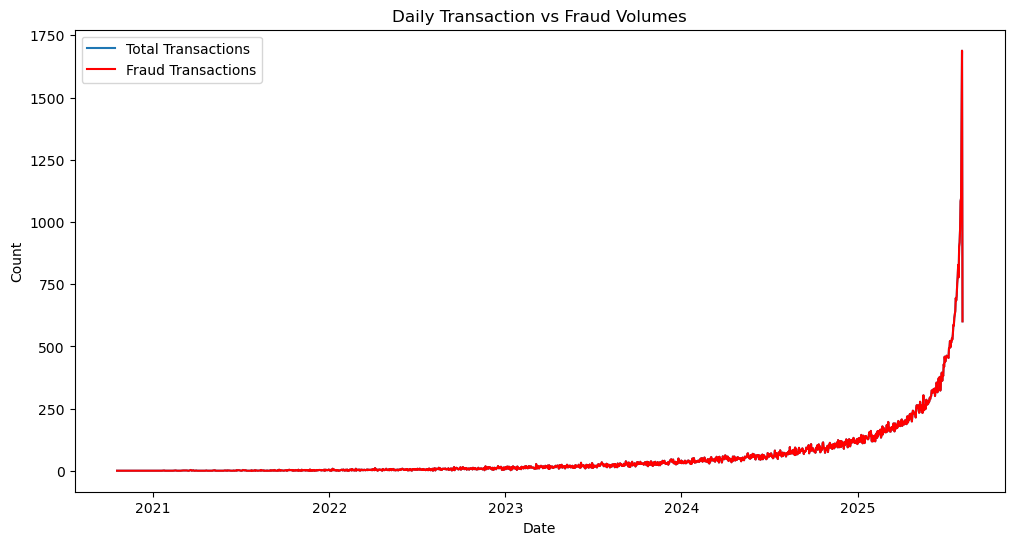

TypeError: Invalid object type at position 0

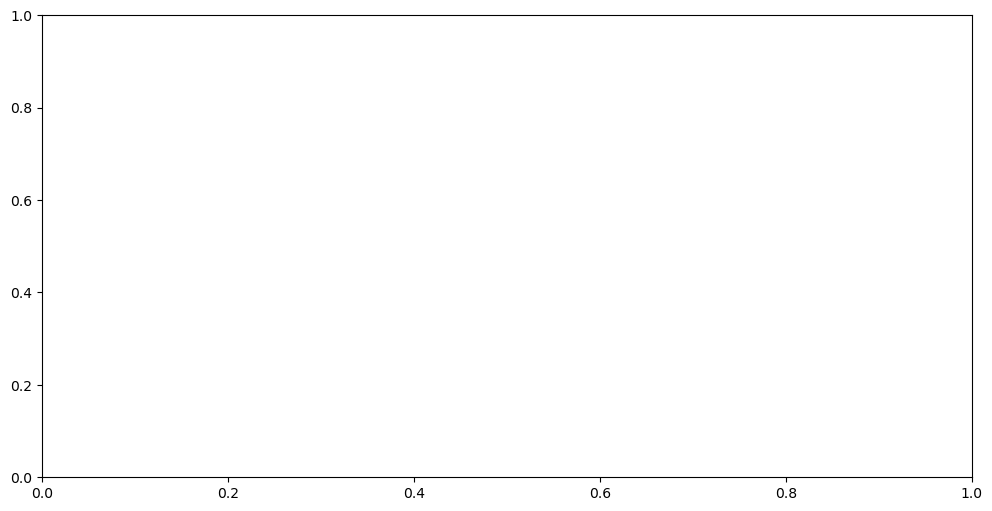

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv("upi_transaction_history.csv")

# Ensure transaction_date is in datetime format
df["timestamp"] = pd.to_datetime(df["timestamp"])

# --- Daily Trends ---
daily_stats = df.groupby(df["timestamp"].dt.date).agg(
    total_txn=("transaction_id", "count"),
    fraud_txn=("fraud_flag", "sum")
).reset_index()

plt.figure(figsize=(12,6))
plt.plot(daily_stats["timestamp"], daily_stats["total_txn"], label="Total Transactions")
plt.plot(daily_stats["timestamp"], daily_stats["total_txn"], label="Fraud Transactions", color="red")
plt.title("Daily Transaction vs Fraud Volumes")
plt.xlabel("Date")
plt.ylabel("Count")
plt.legend()
plt.show()

# --- Monthly Trends ---
monthly_stats = df.groupby(df["timestamp"].dt.to_period("M")).agg(
    total_txn=("transaction_id", "count"),
    fraud_txn=("fraud_flag", "sum")
).reset_index()

plt.figure(figsize=(12,6))
sns.lineplot(x="timestamp", y="total_txn", data=monthly_stats, label="Total Transactions")
sns.lineplot(x="timestamp", y="fraud_flag", data=monthly_stats, label="Fraud Transactions", color="red")
plt.title("Monthly Transaction vs Fraud Volumes")
plt.xlabel("Month")
plt.ylabel("Count")
plt.legend()
plt.show()


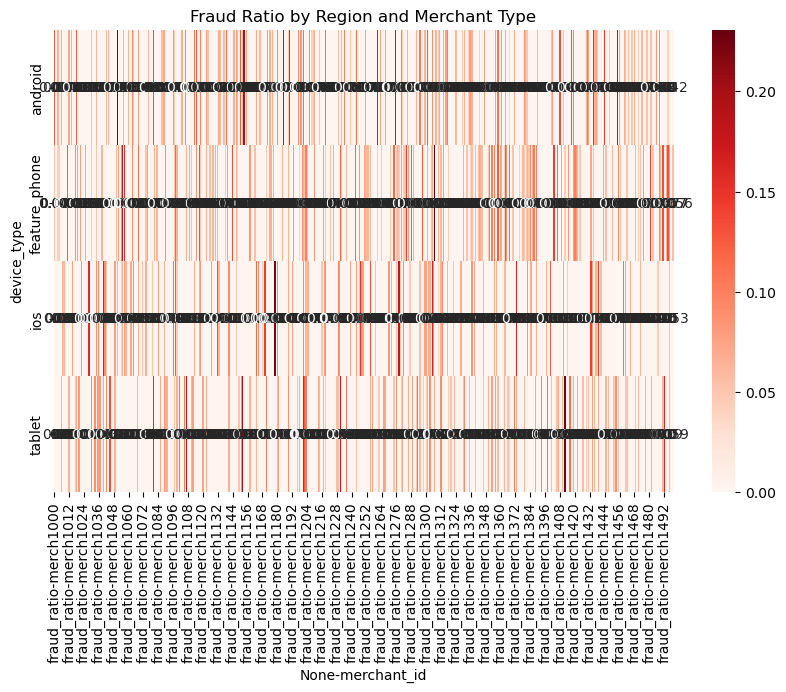

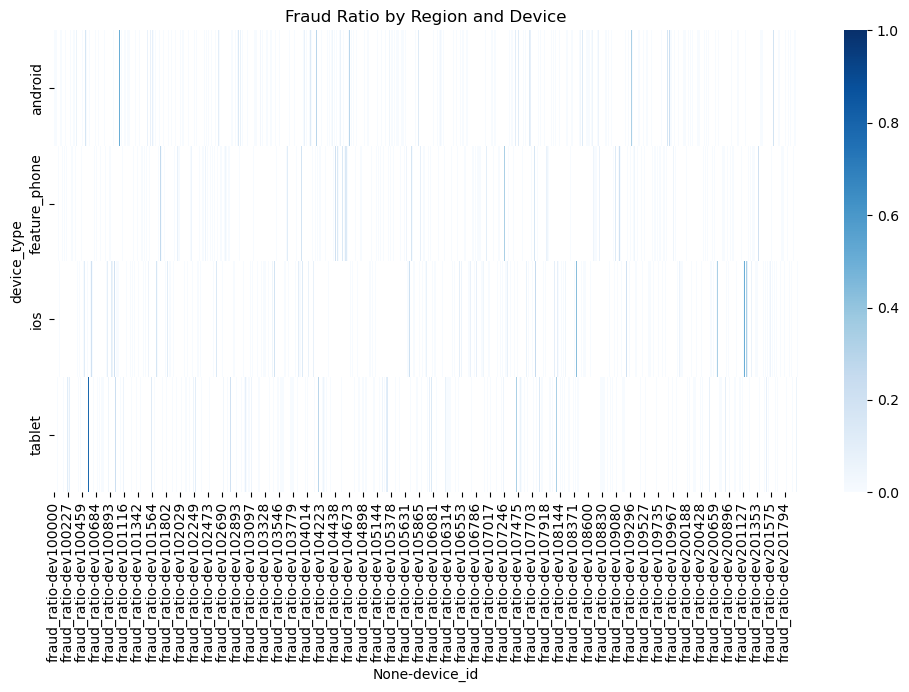

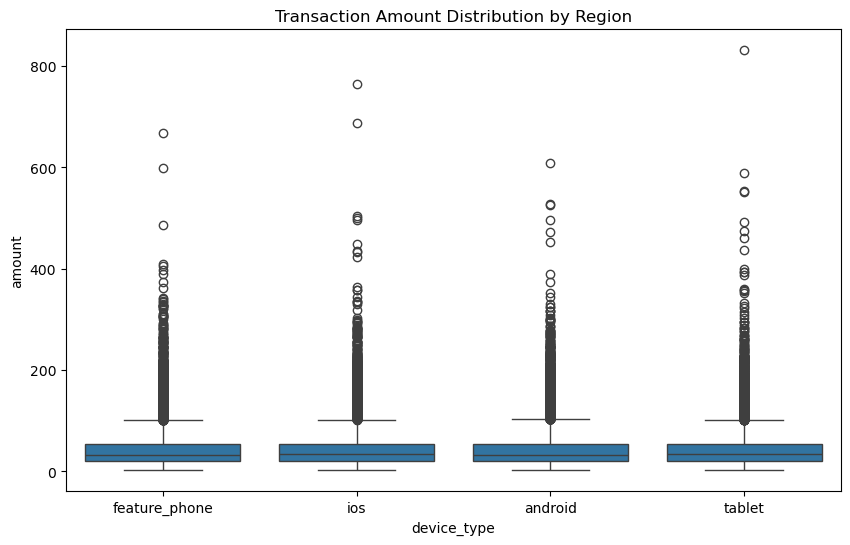

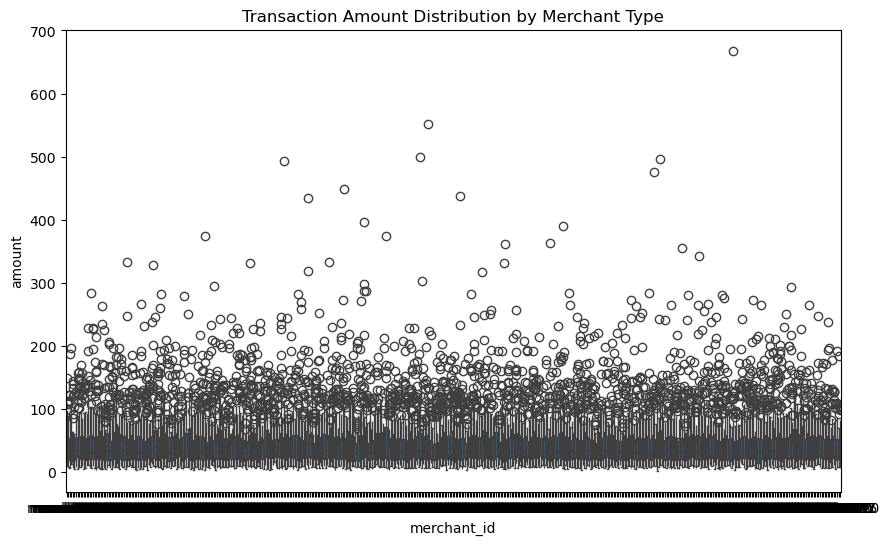

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv("upi_transaction_history.csv")

# --- Fraud Ratio by Region & Merchant Type (Heatmap) ---
fraud_region_merchant = df.groupby(["device_type", "merchant_id"]).agg(
    fraud_ratio=("fraud_flag", "mean")
).unstack()

plt.figure(figsize=(10,6))
sns.heatmap(fraud_region_merchant, annot=True, cmap="Reds")
plt.title("Fraud Ratio by Region and Merchant Type")
plt.show()

# --- Fraud Ratio by Region & Device (Heatmap) ---
fraud_region_device = df.groupby(["device_type", "device_id"]).agg(
    fraud_ratio=("fraud_flag", "mean")
).unstack()

plt.figure(figsize=(12,6))
sns.heatmap(fraud_region_device, cmap="Blues")
plt.title("Fraud Ratio by Region and Device")
plt.show()

# --- Transaction Amount Distribution by Region (Boxplot) ---
plt.figure(figsize=(10,6))
sns.boxplot(x="device_type", y="amount", data=df)
plt.title("Transaction Amount Distribution by Region")
plt.show()

# --- Transaction Amount Distribution by Merchant Type (Boxplot) ---
plt.figure(figsize=(10,6))
sns.boxplot(x="merchant_id", y="amount", data=df)
plt.title("Transaction Amount Distribution by Merchant Type")
plt.show()

# --- Transaction Amount Distribution by Device (Boxplot) ---
plt.figure(figsize=(12,6))
sns.boxplot(x="device_id", y="amount", data=df)
plt.title("Transaction Amount Distribution by Device")
plt.xticks(rotation=90)
plt.show()


### Summarize metrics using grouped statistics (mean, median, standard 
deviation) 
○ Identify high-activity and high-risk segments

In [1]:
import pandas as pd

df = pd.read_csv("merchant_info.csv")

grouped_stats = df.groupby("merchant_type")["risk_score"].agg(
    ["mean", "median", "std"]
).reset_index()

grouped_stats.columns = ["Merchant Type", "Mean Risk Score", "Median Risk Score", "Std Dev Risk Score"]

print(grouped_stats)


  Merchant Type  Mean Risk Score  Median Risk Score  Std Dev Risk Score
0       apparel         0.178673              0.165            0.117917
1   electronics         0.169780              0.150            0.122429
2          food         0.187125              0.180            0.109524
3       grocery         0.168533              0.150            0.120793
4        online         0.173372              0.170            0.117259
5     transport         0.201571              0.220            0.102782


In [3]:
import pandas as pd

merchant_df = pd.read_csv("merchant_info.csv")

txn_df = pd.read_csv("upi_transaction_history.csv")

activity_counts = txn_df["merchant_id"].value_counts().reset_index()
activity_counts.columns = ["merchant_id", "txn_count"]

high_activity_merchants = activity_counts.head(10)
print("High-Activity Merchants:\n", high_activity_merchants)

fraud_ratio = txn_df.groupby("merchant_id")["fraud_flag"].mean().reset_index()
fraud_ratio.columns = ["merchant_id", "fraud_ratio"]

high_risk_merchants = fraud_ratio.sort_values(by="fraud_ratio", ascending=False).head(10)
print("High-Risk Merchants:\n", high_risk_merchants)

high_activity_details = high_activity_merchants.merge(merchant_df, on="merchant_id", how="left")
high_risk_details = high_risk_merchants.merge(merchant_df, on="merchant_id", how="left")

print("\nHigh-Activity Merchant Details:\n", high_activity_details)
print("\nHigh-Risk Merchant Details:\n", high_risk_details)


High-Activity Merchants:
   merchant_id  txn_count
0   merch1310         85
1   merch1138         82
2   merch1131         82
3   merch1476         81
4   merch1004         80
5   merch1315         80
6   merch1318         80
7   merch1212         78
8   merch1487         77
9   merch1019         76
High-Risk Merchants:
     merchant_id  fraud_ratio
201   merch1201     0.106383
305   merch1305     0.086957
358   merch1358     0.080645
80    merch1080     0.075758
364   merch1364     0.074074
203   merch1203     0.071429
231   merch1231     0.070175
307   merch1307     0.070175
51    merch1051     0.069767
219   merch1219     0.068493

High-Activity Merchant Details:
   merchant_id  txn_count                 merchant_name merchant_type   region  \
0   merch1310         85               Donaldson-Patel       apparel    north   
1   merch1138         82      Jones, Adams and Stanley       apparel  central   
2   merch1131         82      Perry, Stewart and Smith        online     west   
